# 5. In-silico Method Comparison
- Plots the cached in-silico benchmark (`6_MethodComparison/cache/plot_data.pkl`, from `notebookscripts/MethodComparison/plot_pr.py`) across arms and log2FC levels.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

os.environ["NM_PIPELINE"] = "p0"
sys.path.insert(0, str(Path.cwd().parents[1]))
from viz_style import apply_style

import MixedEffectsModeling.config as config
from MixedEffectsModeling.notebookscripts.MethodComparison.common import ARMS, COLORS, LABELS, Q_LEVELS, Q_MARKERS, SPLIT_TITLE, STYLES

apply_style()

CACHE = config.METHOD_COMP_CACHE_DIR
FIGDIR = config.METHOD_COMP_FIG_DIR
FIGDIR.mkdir(parents=True, exist_ok=True)

LOG2FCS_SHOWN = [2.0, 3.0, 4.0]



In [2]:
# built by notebookscripts/MethodComparison/plot_pr.py (LOG2FCS_SHOWN must match)
D = pickle.loads((CACHE / f"plot_data_l2fc{'-'.join(f'{f:g}' for f in LOG2FCS_SHOWN)}.pkl").read_bytes())
Q_GRID, RECALL_GRID = D["q_grid"], D["recall_grid"]
print(sorted({f for f, _ in D["cv"]["curves"]}), "log2FC levels cached")

[2.0, 3.0, 4.0, 5.0] log2FC levels cached


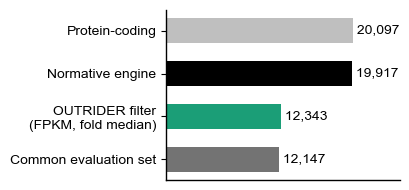

In [3]:
import pandas as pd


def gene_coverage(save=True):
    ts = pd.read_csv(config.ENGINE_DIR / "training_summary.csv")
    latent = [len(pd.read_csv(f)) for f in sorted((CACHE / "LatentFits").glob("autoencoder_*_genes.csv"))]
    n = {"Protein-coding": len(ts),
         "Normative engine": int(ts["ok"].astype(bool).sum()),
         "OUTRIDER filter\n(FPKM, fold median)": int(np.median(latent)),
         "Common evaluation set": len((CACHE / "eval_universe_nm.txt").read_text().split())}
    fig, ax = plt.subplots(figsize=(4.2, 2.0))
    y = np.arange(len(n))
    ax.barh(y, list(n.values()), color=["0.75", "#000000", COLORS["autoencoder"], "0.45"], height=0.6)
    for yi, v in zip(y, n.values()):
        ax.text(v, yi, f" {v:,}", va="center", fontsize=10)
    ax.set_yticks(y); ax.set_yticklabels(list(n.keys()), fontsize=10)
    ax.invert_yaxis(); ax.set_xlim(0, max(n.values()) * 1.25); ax.set_xticks([])
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "gene_coverage.png", dpi=300, bbox_inches="tight")
    return fig


gene_coverage();

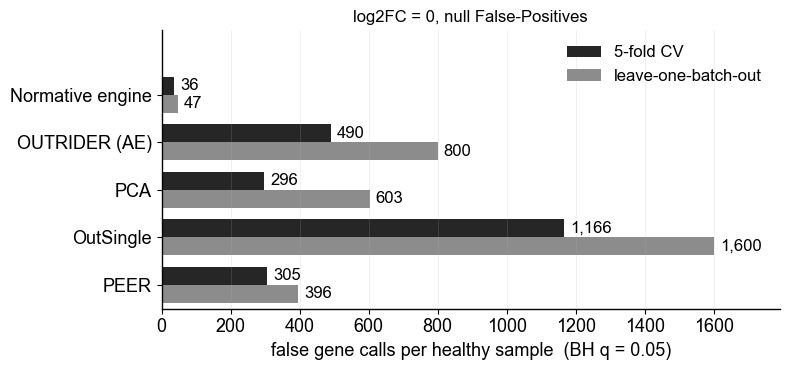

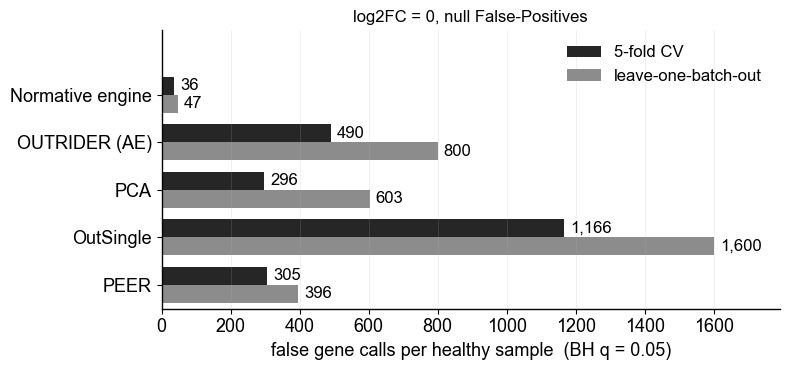

In [4]:
def null_falsecalls(q=0.05, save=True):
    n_genes = len((CACHE / "eval_universe_nm.txt").read_text().split())
    lg = np.log10(np.maximum(Q_GRID, 1e-12))
    rate = lambda sp, a: np.interp(np.log10(q), lg, D["null"][(sp, a)])
    fig, ax = plt.subplots(figsize=(8.0, 3.8))
    h = 0.38
    xmax = max(rate(sp, a) for sp in ("cv", "lobo") for a in ARMS) * n_genes * 1.12
    for k, split in enumerate(("cv", "lobo")):
        y = np.arange(len(ARMS)) + (k - 0.5) * h
        val = np.array([rate(split, a) * n_genes for a in ARMS])
        ax.barh(y, val, height=h, color="0.15" if split == "cv" else "0.55",
                edgecolor="none", label=SPLIT_TITLE[split])
        for yi, v in zip(y, val):
            ax.text(v + xmax * 0.01, yi, f"{v:,.0f}", va="center", fontsize=12)
    ax.set_xlim(0, xmax); ax.set_ylim(len(ARMS) - 0.5, -1.35)
    ax.set_yticks(range(len(ARMS))); ax.set_yticklabels([LABELS[a] for a in ARMS])
    ax.set_xlabel(f"false gene calls per healthy sample  (BH q = {q:g})")
    ax.grid(axis="x", alpha=0.25, lw=0.5)
    ax.legend(frameon=False, fontsize=12, loc="upper right", ncol=1, bbox_to_anchor=(0.995, 1.0))
    ax.set_title("log2FC = 0, null False-Positives", fontsize=12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "null_falsecalls.png", dpi=300, bbox_inches="tight")
    return fig

null_falsecalls()

In [5]:
# Inflation factor: observed / nominal. 1.0 = perfectly calibrated, >1 = anti-conservative.
import pandas as pd

alphas = [1e-4, 1e-3, 1e-2, 0.05]
idx = np.searchsorted(Q_GRID, alphas)
rows = {(SPLIT_TITLE[s], LABELS[a]): D["pcal"][(s, a)][idx] / np.array(alphas)
        for s in ("cv", "lobo") for a in ARMS}
pd.DataFrame(rows, index=[f"alpha={a:g}" for a in alphas]).T.round(2)

alpha=0.0001  alpha=0.001  alpha=0.01  \
5-fold CV           Normative engine         13.37         3.83        1.64   
                    OUTRIDER (AE)           220.65        30.11        4.86   
                    PCA                     113.19        17.45        3.19   
                    OutSingle               419.75        61.82       10.40   
                    PEER                    102.18        17.19        3.53   
leave-one-batch-out Normative engine         18.24         5.08        1.97   
                    OUTRIDER (AE)           347.05        47.41        7.57   
                    PCA                     228.93        34.04        5.82   
                    OutSingle               562.03        82.83       13.71   
                    PEER                    129.90        22.09        4.53   

                                      alpha=0.05  
5-fold CV           Normative engine        1.20  
                    OUTRIDER (AE)           1.67  
                    PCA                     1.19  
                    OutSingle               3.45  
                    PEER                    1.45  
leave-one-batch-out Normative engine        1.34  
                    OUTRIDER (AE)           2.51  
                    PCA                     1.99  
                    OutSingle               4.39  
                    PEER                    1.84

In [6]:
def pr_grid(log2fcs=LOG2FCS_SHOWN, splits=("cv", "lobo"), arms=ARMS, band=True, save=True):
    """Line = per-fold median, ribbon = fold IQR, markers = the reported BH levels placed at
    the median recall reached there and read off the curve, so they sit ON the line."""
    fig, axes = plt.subplots(len(splits), len(log2fcs),
                             figsize=(2.7 * len(log2fcs), 2.4 * len(splits)),
                             sharex=True, sharey=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, f in enumerate(log2fcs):
            ax = axes[i, j]
            bands, ops = D[split]["bands"], D[split]["ops"]
            for arm in arms:
                lo, med, hi = bands[(f, arm)]
                if band:
                    ax.fill_between(RECALL_GRID, lo, hi, color=COLORS[arm], alpha=0.15, lw=0)
                ax.plot(RECALL_GRID, med, color=COLORS[arm], ls=STYLES[arm],
                        lw=2.0 if arm == "engine" else 1.4,
                        label=LABELS[arm] if (i, j) == (0, 0) else None,
                        zorder=4 if arm == "engine" else 3)
                for q in Q_LEVELS:
                    r = ops[("med", q, f, arm)][0]
                    ax.plot(r, np.interp(r, RECALL_GRID, med), marker=Q_MARKERS[q], ms=6,
                            color=COLORS[arm], mec="white", mew=0.6, ls="none", zorder=5)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.2, lw=0.5)
            if i == 0:
                ax.set_title(f"log2FC = {f:g}")
            if j == len(log2fcs) - 1:
                ax.text(1.06, 0.5, SPLIT_TITLE[split], rotation=270, va="center",
                        ha="left", fontsize=12, transform=ax.transAxes,
                        bbox=dict(facecolor="0.92", edgecolor="none", pad=3))
            if j == 0:
                ax.set_ylabel("Precision")
            if i == len(splits) - 1:
                ax.set_xlabel("Recall")
    h, l = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, l, loc="upper left", bbox_to_anchor=(1.02, 0.95), frameon=False,
                     fontsize=12, title="Method")
    leg.get_title().set_fontsize(12)
    qh = [plt.Line2D([], [], marker=m, ls="none", color="0.3", ms=4, mec="white", mew=0.6)
          for m in Q_MARKERS.values()]
    leg2 = fig.legend(qh, [str(q) for q in Q_MARKERS], loc="upper left",
                      bbox_to_anchor=(1.02, 0.55), frameon=False, fontsize=12, title="BH q")
    leg2.get_title().set_fontsize(12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "pr_grid.png", dpi=300, bbox_inches="tight")
    return fig

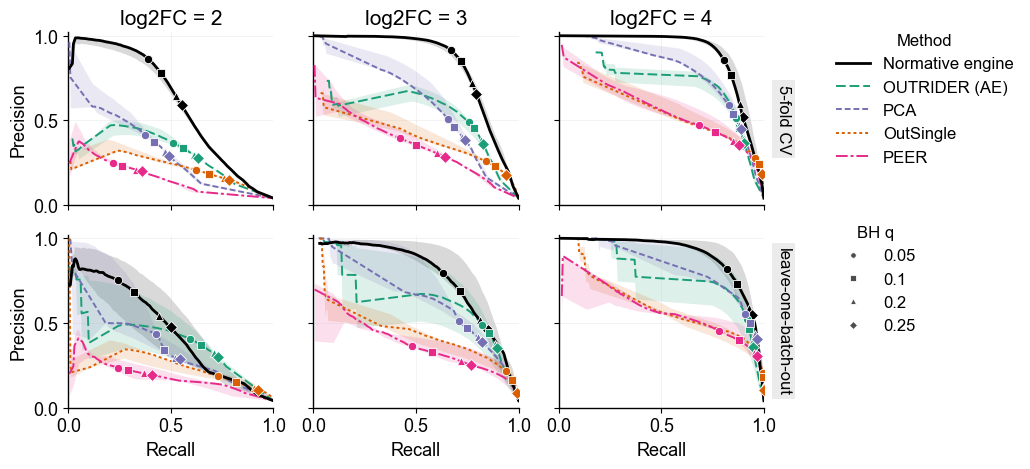

In [7]:
pr_grid();

In [8]:
def persample_confusion(q=0.05):
    c = pd.read_csv(CACHE / "sweep_nm_counts.csv")
    c = c[(c["q"] == q) & c["log2fc"].isin([0.0] + LOG2FCS_SHOWN)].groupby(["split", "arm", "log2fc"])[["tp", "fp", "fn", "tn", "n_samples"]].sum()
    out = c[["tp", "fp", "fn", "tn"]].div(c["n_samples"], axis=0)
    out.columns = ["TP", "FP", "FN", "TN"]
    return out


CONF = persample_confusion()
CONF.unstack("log2fc").round(1)

TP                           FP                          \
log2fc              0.0    2.0    3.0    4.0     0.0     2.0     3.0     4.0   
split arm                                                                      
cv    autoencoder  20.1  260.4  380.6  435.1   469.8   459.0   447.6   435.5   
      engine        1.4  194.0  334.8  403.2    34.5    39.9    41.2    59.9   
      outsingle    47.8  309.3  416.8  477.0  1118.4  1163.3  1187.6  1204.7   
      pca          12.2  192.5  324.5  412.0   284.2   283.4   286.2   284.0   
      peer         12.4  106.3  216.8  338.4   292.6   307.3   326.4   341.3   
lobo  autoencoder  32.9  288.0  397.8  444.9   767.3   764.7   750.9   736.9   
      engine        2.0  151.4  302.2  379.6    44.7    54.2    52.5    58.9   
      outsingle    65.4  337.5  436.7  483.9  1534.3  1578.0  1603.5  1622.2   
      pca          24.9  234.9  360.3  439.1   577.8   568.9   568.4   561.4   
      peer         16.1  120.2  240.3  367.7   379.6   404.8   430.7   449.4   

                      FN                            TN                    \
log2fc               0.0    2.0    3.0    4.0      0.0      2.0      3.0   
split arm                                                                  
cv    autoencoder  479.9  239.6  119.4   64.9  11177.2  11188.0  11199.4   
      engine       498.6  306.0  165.2   96.8  11612.5  11607.1  11605.8   
      outsingle    452.2  190.7   83.2   23.0  10528.6  10483.7  10459.4   
      pca          487.8  307.5  175.5   88.0  11362.8  11363.6  11360.8   
      peer         487.6  393.7  283.2  161.6  11354.4  11339.7  11320.6   
lobo  autoencoder  467.1  212.0  102.2   55.1  10879.7  10882.3  10896.1   
      engine       498.0  348.6  197.8  120.4  11602.3  11592.8  11594.5   
      outsingle    434.6  162.5   63.3   16.1  10112.7  10069.0  10043.5   
      pca          475.1  265.1  139.7   60.9  11069.2  11078.1  11078.6   
      peer         483.9  379.8  259.7  132.3  11267.4  11242.2  11216.3   

                            
log2fc                 4.0  
split arm                   
cv    autoencoder  11211.5  
      engine       11587.1  
      outsingle    10442.3  
      pca          11363.0  
      peer         11305.7  
lobo  autoencoder  10910.1  
      engine       11588.1  
      outsingle    10024.8  
      pca          11085.6  
      peer         11197.6

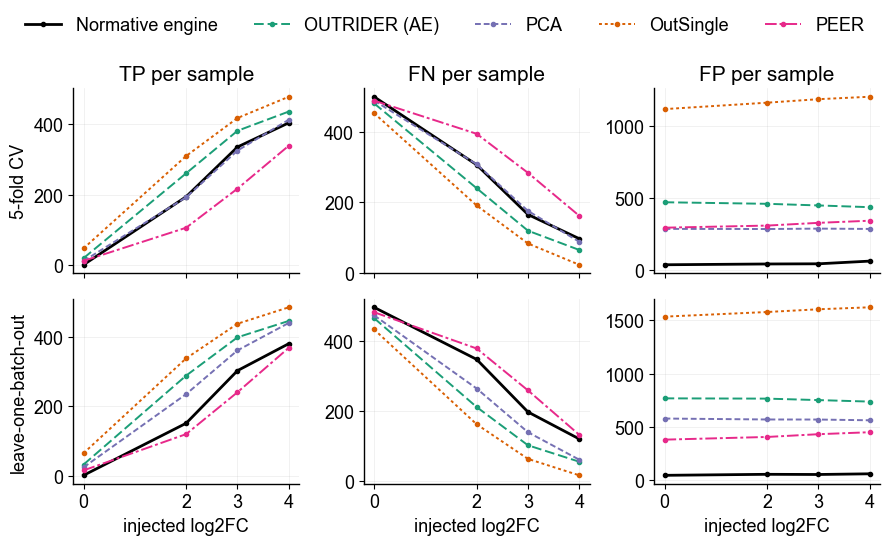

In [9]:
def confusion_panels(conf=CONF, splits=("cv", "lobo"), arms=ARMS, save=True):
    metrics = ["TP", "FN", "FP"]
    fig, axes = plt.subplots(len(splits), len(metrics), figsize=(3 * len(metrics), 2.5 * len(splits)),
                             sharex=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, m in enumerate(metrics):
            ax = axes[i, j]
            for arm in arms:
                s = conf.loc[(split, arm), m]
                ax.plot(s.index, s.values, color=COLORS[arm], ls=STYLES[arm], marker="o", ms=3,
                        lw=2.0 if arm == "engine" else 1.4, label=LABELS[arm] if (i, j) == (0, 0) else None)
            if i == 0:
                ax.set_title(f"{m} per sample")
            if j == 0:
                ax.set_ylabel(SPLIT_TITLE[split])
            if i == len(splits) - 1:
                ax.set_xlabel("injected log2FC")
            ax.set_xticks(conf.index.get_level_values("log2fc").unique())
            ax.grid(alpha=0.25, lw=0.5)
    fig.legend(loc="upper center", ncol=len(arms), frameon=False, bbox_to_anchor=(0.5, 1.1))
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "persample_confusion.png", dpi=300, bbox_inches="tight")
    return fig


confusion_panels();